# Breast Cancer Classification

**Problem:** From 30 measurements computed from a breast-mass cell image, predict whether the tumour is **malignant** or **benign**.

**Dataset:** Wisconsin Diagnostic Breast Cancer dataset (built into scikit-learn) — 569 samples, 30 numeric features. *Educational project — not a medical tool.*

**Approach:** standardize features, compare Logistic Regression and Random Forest.

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

data = load_breast_cancer()
X, y = data.data, data.target  # 0 = malignant, 1 = benign
print("Samples:", X.shape, "| Malignant:", int((y == 0).sum()), "| Benign:", int((y == 1).sum()))
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(X_tr)
Xtr, Xte = sc.transform(X_tr), sc.transform(X_te)

Samples: (569, 30) | Malignant: 212 | Benign: 357


Logistic Regression accuracy: 0.986
Random Forest accuracy: 0.958
              precision    recall  f1-score   support

   Malignant      0.981     0.981     0.981        53
      Benign      0.989     0.989     0.989        90

    accuracy                          0.986       143
   macro avg      0.985     0.985     0.985       143
weighted avg      0.986     0.986     0.986       143



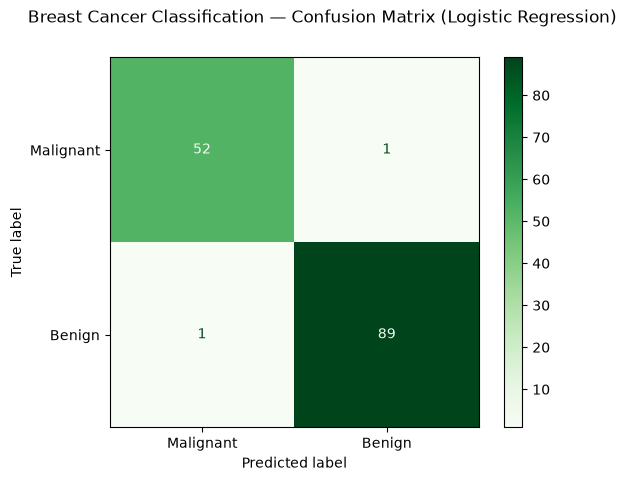

In [2]:
lr = LogisticRegression(max_iter=5000).fit(Xtr, y_tr)
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_tr, y_tr)
for name, m, Xt in [("Logistic Regression", lr, Xte), ("Random Forest", rf, X_te)]:
    print(name, "accuracy:", round(accuracy_score(y_te, m.predict(Xt)), 4))
print(classification_report(y_te, lr.predict(Xte), target_names=["Malignant", "Benign"], digits=3))
disp = ConfusionMatrixDisplay.from_predictions(y_te, lr.predict(Xte), display_labels=["Malignant", "Benign"], cmap="Greens")
disp.figure_.suptitle("Breast Cancer Classification — Confusion Matrix (Logistic Regression)")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

## Result
**Logistic Regression: 98.6% accuracy; Random Forest: 95.8%** (executed output above). In a medical setting the malignant recall matters most — a missed malignant case is the expensive error — which is why the classification report, not just accuracy, is shown.